# Proyecto Electromagnetismo II

## Dispersión de Thomson de una onda electromagnética por un electrón libre

**Daniel Coto Céspedes**

**Anthony Madrigal Salazar**



## Enunciado del problema

Considere una onda electromagnética plana y monocromática que se propaga en el vacío en la dirección $+\hat{\mathbf z}$, con polarización lineal en $\hat{\mathbf x}$. Un electrón libre se encuentra inicialmente cerca del origen.

Se desea visualizar, a partir de soluciones analíticas, cómo el campo eléctrico incidente induce una oscilación del electrón y cómo esta aceleración produce radiación electromagnética dispersada. El programa deberá representar el patrón angular tridimensional de la radiación, relacionarlo con el vector de Poynting y obtener la sección eficaz diferencial de Thomson.

La visualización permitirá estudiar la relación entre la polarización de la onda incidente y las direcciones en las que la radiación dispersada es máxima o nula.


## Objetivos

### Objetivo general

Visualizar la dispersión clásica de Thomson a partir de la interacción entre una onda electromagnética plana y un electrón libre, utilizando soluciones analíticas de las ecuaciones electromagnéticas y de la ecuación de movimiento.

### Objetivos específicos

1. Describir la onda incidente como una solución plana monocromática de las ecuaciones de Maxwell.
2. Obtener analíticamente el movimiento del electrón en el régimen no relativista.
3. Calcular el campo electromagnético radiado por el electrón acelerado.
4. Relacionar el campo dispersado con el vector de Poynting y la potencia radiada.
5. Visualizar en tres dimensiones el patrón angular de dispersión.
6. Obtener la sección eficaz diferencial de Thomson y verificar su sección eficaz total.


## 1. Onda electromagnética incidente

En el vacío y en ausencia de cargas y corrientes,

$$
\nabla\cdot\mathbf E=0,
\qquad
\nabla\cdot\mathbf B=0,
$$

$$
\nabla\times\mathbf E
=
-\frac{\partial\mathbf B}{\partial t},
\qquad
\nabla\times\mathbf B
=
\mu_0\varepsilon_0
\frac{\partial\mathbf E}{\partial t}.
$$

De estas ecuaciones se obtiene la ecuación de onda

$$
\nabla^2\mathbf E
=
\frac{1}{c^2}
\frac{\partial^2\mathbf E}{\partial t^2},
\qquad
\nabla^2\mathbf B
=
\frac{1}{c^2}
\frac{\partial^2\mathbf B}{\partial t^2},
$$

con

$$
c=\frac{1}{\sqrt{\mu_0\varepsilon_0}}.
$$

Tomamos una onda plana monocromática que se propaga en $+\hat{\mathbf z}$ y está polarizada en $\hat{\mathbf x}$:

$$
\mathbf E_{\rm I}(z,t)
=
E_0\cos(kz-\omega t)\,\hat{\mathbf x}
$$

y, usando

$$
\mathbf B_{\rm I}
=
\frac{1}{c}\hat{\mathbf k}\times\mathbf E_{\rm I},
$$

se obtiene

$$
\mathbf B_{\rm I}(z,t)
=
\frac{E_0}{c}
\cos(kz-\omega t)\,\hat{\mathbf y}
$$

Por tanto,

$$
\mathbf E_{\rm I}\perp
\mathbf B_{\rm I}\perp
\mathbf k.
$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from scipy.constants import c, e, m_e, epsilon_0, pi

%matplotlib inline


In [2]:

# Parámetros de la onda incidente

wavelength = 500e-9       # m
E0 = 1e6                  # V/m

k = 2*pi/wavelength
omega = c*k
T = 2*pi/omega

print(f"lambda = {wavelength:.3e} m")
print(f"omega  = {omega:.3e} rad/s")
print(f"T      = {T:.3e} s")


lambda = 5.000e-07 m
omega  = 3.767e+15 rad/s
T      = 1.668e-15 s


## 2. Movimiento del electrón

La fuerza de Lorentz sobre un electrón es

$$
\mathbf F
=
-e\left(
\mathbf E+\mathbf v\times\mathbf B
\right).
$$

En el régimen de Thomson el movimiento es no relativista, $v\ll c$. Como para una onda en el vacío $B=E/c$, la razón entre las magnitudes de las fuerzas magnética y eléctrica es aproximadamente

$$
\frac{F_B}{F_E}
\sim
\frac{v}{c}.
$$

Por tanto, a primer orden,

$$
\mathbf F\simeq-e\mathbf E.
$$

Además, si el desplazamiento del electrón es mucho menor que la longitud de onda,

$$
|\mathbf r_e|\ll\lambda,
$$

el campo puede evaluarse en la posición inicial del electrón, $z\simeq0$. Así,

$$
\mathbf E_{\rm inc}(0,t)
=
E_0\cos(\omega t)\,\hat{\mathbf x}.
$$

La ecuación de movimiento es entonces

$$
m_e\ddot x
=
-eE_0\cos(\omega t).
$$

Una solución oscilatoria sin velocidad de deriva es

$$
x(t)
=
\frac{eE_0}{m_e\omega^2}
\cos(\omega t)
$$

y, por tanto,

$$
v_x(t)
=
-\frac{eE_0}{m_e\omega}
\sin(\omega t)
$$

$$
a_x(t)
=
-\frac{eE_0}{m_e}
\cos(\omega t)
$$

La onda incidente obliga al electrón a oscilar en la dirección de su polarización.


In [3]:
t = np.linspace(0, 5*T, 1500)

x0 = e*E0/(m_e*omega**2)
v0 = e*E0/(m_e*omega)
a0 = e*E0/m_e

x = x0*np.cos(omega*t)
vx = -v0*np.sin(omega*t)
ax = -a0*np.cos(omega*t)

print(f"x0 = {x0:.3e} m")
print(f"v_max/c = {v0/c:.3e}")
print(f"x0/lambda = {x0/wavelength:.3e}")


x0 = 1.239e-14 m
v_max/c = 1.557e-07
x0/lambda = 2.479e-08


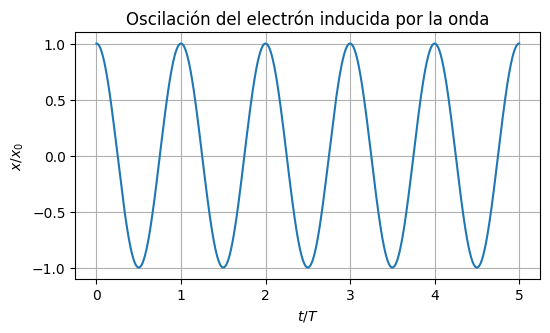

In [4]:
fig, ax_plot = plt.subplots(figsize=(6, 3.2))

ax_plot.plot(t/T, x/x0)

ax_plot.set_xlabel(r"$t/T$")
ax_plot.set_ylabel(r"$x/x_0$")
ax_plot.set_title("Oscilación del electrón inducida por la onda")
ax_plot.grid()

plt.show()


Los dos cocientes

$$
\frac{v_{\max}}{c}
=
\frac{eE_0}{m_e\omega c}
$$

y

$$
\frac{x_0}{\lambda}
=
\frac{eE_0}{m_e\omega^2\lambda}
$$

permiten comprobar directamente la consistencia de las aproximaciones empleadas:

$$
v\ll c,
\qquad
x_0\ll\lambda.
$$


## 3. Campo electromagnético dispersado

Una carga acelerada produce radiación electromagnética. En la zona lejana, el campo eléctrico radiativo de una carga no relativista es

$$
\mathbf E_{\rm rad}(\mathbf R,t)
=
\frac{q}
{4\pi\varepsilon_0c^2R}
\,
\hat{\mathbf n}
\times
\left[
\hat{\mathbf n}
\times
\mathbf a(t_{\rm ret})
\right]
$$

donde

$$
\hat{\mathbf n}
=
\frac{\mathbf R}{R},
\qquad
t_{\rm ret}=t-\frac{R}{c}.
$$

Para el electrón, $q=-e$. El campo magnético radiado satisface

$$
\mathbf B_{\rm rad}
=
\frac{1}{c}
\hat{\mathbf n}\times\mathbf E_{\rm rad}
$$

Por tanto, la onda dispersada también es transversal.


### Distribución angular de la potencia

El vector de Poynting de la radiación dispersada es

$$
\mathbf S_{\rm rad}
=
\frac{1}{\mu_0}
\mathbf E_{\rm rad}\times\mathbf B_{\rm rad}.
$$

En la zona lejana,

$$
S_{\rm rad}
=
\varepsilon_0c
|\mathbf E_{\rm rad}|^2.
$$

La potencia radiada por unidad de ángulo sólido es

$$
\frac{dP}{d\Omega}
=
\frac{e^2}
{16\pi^2\varepsilon_0c^3}
\left\langle
\left|
\hat{\mathbf n}\times
(\hat{\mathbf n}\times\mathbf a)
\right|^2
\right\rangle
$$

Como la aceleración está dirigida en $\hat{\mathbf x}$,

$$
\mathbf a(t)
=
-a_0\cos(\omega t)\hat{\mathbf x},
\qquad
a_0=\frac{eE_0}{m_e}.
$$

Tomamos

$$
\hat{\mathbf n}
=
\sin\theta\cos\phi\,\hat{\mathbf x}
+
\sin\theta\sin\phi\,\hat{\mathbf y}
+
\cos\theta\,\hat{\mathbf z}.
$$

Entonces

$$
\hat{\mathbf n}\cdot\hat{\mathbf x}
=
\sin\theta\cos\phi,
$$

y utilizando

$$
\left|
\hat{\mathbf n}\times
(\hat{\mathbf n}\times\mathbf a)
\right|^2
=
a^2-
(\hat{\mathbf n}\cdot\mathbf a)^2,
$$

se obtiene

$$
\left|
\hat{\mathbf n}\times
(\hat{\mathbf n}\times\mathbf a)
\right|^2
=
a_0^2\cos^2(\omega t)
\left(
1-\sin^2\theta\cos^2\phi
\right).
$$

Como

$$
\left\langle\cos^2(\omega t)\right\rangle
=
\frac12,
$$

la distribución angular promedio queda

$$
\frac{dP}{d\Omega}
=
\frac{e^4E_0^2}
{32\pi^2\varepsilon_0m_e^2c^3}
\left(
1-\sin^2\theta\cos^2\phi
\right)
$$


In [5]:
theta = np.linspace(0, pi, 180)
phi = np.linspace(0, 2*pi, 360)

theta_grid, phi_grid = np.meshgrid(theta, phi, indexing="ij")

angular_factor = (
    1
    - np.sin(theta_grid)**2
    * np.cos(phi_grid)**2
)

prefactor = (
    e**4 * E0**2
    / (32*pi**2 * epsilon_0 * m_e**2 * c**3)
)

dP_dOmega = prefactor * angular_factor
P_norm = dP_dOmega / np.max(dP_dOmega)


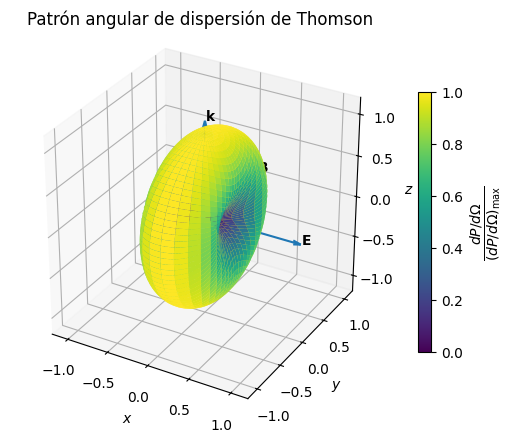

In [6]:
R_plot = P_norm

X = R_plot*np.sin(theta_grid)*np.cos(phi_grid)
Y = R_plot*np.sin(theta_grid)*np.sin(phi_grid)
Z = R_plot*np.cos(theta_grid)

norm = colors.Normalize(vmin=0, vmax=1)
cmap = cm.viridis
facecolors = cmap(norm(P_norm))

fig = plt.figure(figsize=(6.2, 5.2))
ax3d = fig.add_subplot(111, projection="3d")

ax3d.plot_surface(
    X, Y, Z,
    facecolors=facecolors,
    linewidth=0,
    antialiased=True,
    shade=False
)

mappable = cm.ScalarMappable(norm=norm, cmap=cmap)
mappable.set_array(P_norm)

cbar = fig.colorbar(
    mappable,
    ax=ax3d,
    shrink=0.65,
    pad=0.06
)

cbar.set_label(
    r"$\dfrac{dP/d\Omega}{(dP/d\Omega)_{\rm max}}$"
)

L = 1.15

ax3d.quiver(0, 0, 0, L, 0, 0, arrow_length_ratio=0.08)
ax3d.text(L, 0, 0, r"$\mathbf{E}$")

ax3d.quiver(0, 0, 0, 0, L, 0, arrow_length_ratio=0.08)
ax3d.text(0, L, 0, r"$\mathbf{B}$")

ax3d.quiver(0, 0, 0, 0, 0, L, arrow_length_ratio=0.08)
ax3d.text(0, 0, L, r"$\mathbf{k}$")

ax3d.set_xlabel(r"$x$")
ax3d.set_ylabel(r"$y$")
ax3d.set_zlabel(r"$z$")
ax3d.set_title("Patrón angular de dispersión de Thomson")

ax3d.set_box_aspect((1, 1, 1))
ax3d.set_xlim(-1.2, 1.2)
ax3d.set_ylim(-1.2, 1.2)
ax3d.set_zlim(-1.2, 1.2)

plt.show()


### Interpretación física del patrón

El electrón oscila en la dirección del campo eléctrico incidente, es decir, a lo largo de $\hat{\mathbf x}$. Por esta razón, la radiación tiene el patrón característico de un dipolo oscilante.

La potencia se anula cuando la dirección de observación es paralela a la aceleración,

$$
\hat{\mathbf n}\parallel\hat{\mathbf x},
$$

y es máxima cuando

$$
\hat{\mathbf n}\perp\hat{\mathbf x}.
$$

La visualización tridimensional permite observar directamente que la dispersión no depende únicamente del ángulo respecto a la dirección de propagación $\hat{\mathbf z}$: para una onda linealmente polarizada también depende de la orientación respecto al campo eléctrico incidente.


## 4. Sección eficaz diferencial de Thomson

La intensidad promedio de la onda incidente es

$$
I_{\rm inc}
=
\frac12\varepsilon_0cE_0^2
$$

La sección eficaz diferencial se define mediante

$$
\frac{d\sigma}{d\Omega}
=
\frac{1}{I_{\rm inc}}
\frac{dP}{d\Omega}
$$

Sustituyendo la expresión obtenida para $dP/d\Omega$,

$$
\frac{d\sigma}{d\Omega}
=
\frac{e^4}
{16\pi^2\varepsilon_0^2m_e^2c^4}
\left(
1-\sin^2\theta\cos^2\phi
\right).
$$

Definiendo el radio clásico del electrón,

$$
r_e=
\frac{e^2}
{4\pi\varepsilon_0m_ec^2},
$$

se obtiene finalmente

$$
\frac{d\sigma}{d\Omega}
=
r_e^2
\left(
1-\sin^2\theta\cos^2\phi
\right)
$$

Este es el resultado de Thomson para una onda incidente linealmente polarizada en $\hat{\mathbf x}$.


In [7]:
r_e = e**2/(4*pi*epsilon_0*m_e*c**2)

dsigma_dOmega = (
    r_e**2
    * angular_factor
)

print(f"Radio clásico del electrón: r_e = {r_e:.6e} m")
print(
    "Máximo de dσ/dΩ = "
    f"{np.max(dsigma_dOmega):.6e} m²/sr"
)


Radio clásico del electrón: r_e = 2.817940e-15 m
Máximo de dσ/dΩ = 7.940788e-30 m²/sr


## 5. Radiación incidente no polarizada

Si la radiación incidente no tiene una dirección de polarización preferente, se promedia sobre dos polarizaciones lineales ortogonales. El resultado es

$$
\left\langle
\frac{d\sigma}{d\Omega}
\right\rangle_{\rm pol}
=
\frac{r_e^2}{2}
\left(
1+\cos^2\theta
\right)
$$

Al integrar sobre todo el ángulo sólido,

$$
\sigma_T
=
\int
\frac{d\sigma}{d\Omega}\,d\Omega,
$$

se obtiene la sección eficaz total de Thomson,

$$
\sigma_T
=
\frac{8\pi}{3}r_e^2
$$


In [8]:
sigma_T = (8*pi/3)*r_e**2

print(f"Sección eficaz total de Thomson = {sigma_T:.6e} m²")


Sección eficaz total de Thomson = 6.652459e-29 m²


## Interpretación física de los resultados

La onda incidente transfiere energía al movimiento oscilatorio del electrón mediante su campo eléctrico. El electrón acelerado actúa como una fuente secundaria de ondas electromagnéticas.

La distribución de la radiación dispersada está determinada por la dirección de la aceleración: una carga acelerada no radia a lo largo del eje de su aceleración y radia con máxima intensidad en las direcciones perpendiculares.

Esto explica por qué la polarización de la onda incidente deja una firma directa en el patrón angular de dispersión.


## Retrospectiva de la visualización

**Elemento comprendido mejor mediante la visualización:**

La gráfica tridimensional permite comprender con mayor claridad que el patrón de Thomson para luz linealmente polarizada no es simplemente una función del ángulo respecto a la dirección de propagación.

Las ecuaciones muestran el factor

$$
1-\sin^2\theta\cos^2\phi,
$$

pero la superficie 3D permite identificar inmediatamente los dos nodos en la dirección de polarización $\pm\hat{\mathbf x}$ y el máximo continuo en el plano perpendicular a ella.

Físicamente, esto ocurre porque el electrón oscila en la dirección del campo eléctrico incidente y la radiación de una carga acelerada es transversal respecto a su aceleración.


## Videos Ilustrativos de la Dispersión de Thomson

Junto con el notebook, se incluyen algunos videos ilustrativos, elaborados con manim (https://www.manim.community/). Tanto para 2D como para 3D, se muestran tres videos: el etiquetado como "Normal", el etiquetado como "Low_Wavelength" y el etiquetado como "High_Field_Strength". Se ilustran los siguientes puntos.

1. Al aumentar la fuerza del campo eléctrico del fotón incidente, aumenta la amplitud de la oscilación del electrón. Se puede observar esto al comparar el video "High_Field_Strength" con el "Normal". En general, se exagera sustancialmente el movimiento al vaivén, aunque en realidad, a este nivel de energía, el electrón no sufriría una mayor perturbación.
2. Al disminuir la longitud de onda del fotón incidente, aumenta la frecuencia de oscilación del electrón. Esto se puede obesrvar comparando el video "Low_Wavelength" con el "Normal".

Se incluye el código de Manim al lado del notebook. No es la intención correrlo en una celda. Se debe correr en una instalación local correcta como `manim -pql thomson.py`.

## Extensión: del régimen de Thomson al efecto Compton

La dispersión de Thomson supone que la energía transferida al electrón es
despreciable y, por tanto, la frecuencia de la radiación dispersada es
prácticamente la misma que la de la onda incidente.

Cuando la energía de la radiación aumenta, esta aproximación deja de ser
válida. En la descripción de Compton, la radiación intercambia energía y
momento con el electrón.

Para un electrón inicialmente en reposo, la longitud de onda dispersada
satisface

$$
\lambda' - \lambda
=
\frac{h}{m_e c}
\left(
1-\cos\theta
\right)
$$

donde $\theta$ es el ángulo entre la dirección incidente y la dirección
de la radiación dispersada.

Equivalentemente, en términos de la energía de la radiación,

$$
E'
=
\frac{E}{
1+
\frac{E}{m_e c^2}
\left(
1-\cos\theta
\right)
}
$$

Si

$$
E\ll m_e c^2,
$$

entonces

$$
E'\simeq E,
$$

por lo que el cambio de frecuencia es despreciable y se recupera el
régimen clásico de Thomson.

Así, la dispersión de Thomson puede interpretarse como el límite de baja
energía de la dispersión de Compton.

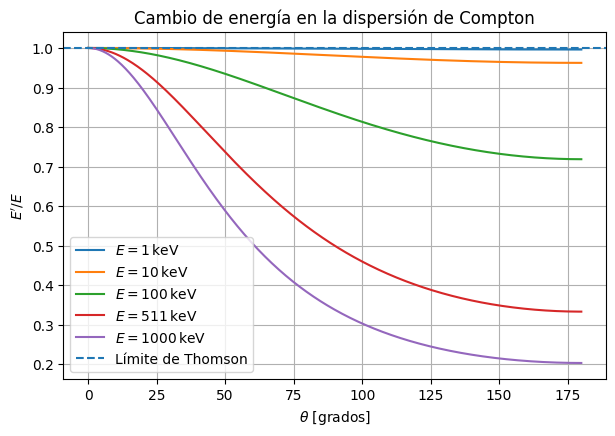

In [9]:
from scipy.constants import h, electron_volt

mec2_keV = m_e * c**2 / (1e3 * electron_volt)

theta_C = np.linspace(0, pi, 500)

energies = [1, 10, 100, 511, 1000]

fig, ax = plt.subplots(figsize=(7, 4.5))

for E in energies:

    E_prime = E / (
        1
        + (E/mec2_keV)
        * (1 - np.cos(theta_C))
    )

    ax.plot(
        np.degrees(theta_C),
        E_prime/E,
        label=fr"$E={E}\,\mathrm{{keV}}$"
    )

ax.axhline(
    1,
    linestyle="--",
    label="Límite de Thomson"
)

ax.set_xlabel(r"$\theta$ [grados]")
ax.set_ylabel(r"$E'/E$")

ax.set_title(
    "Cambio de energía en la dispersión de Compton"
)

ax.legend()
ax.grid()

plt.show()

## Videos Ilustrativos de la Dispersión de Compton

Se incluyen también dos videos ilustrativos del caso de Compton. En uno, la dispersión del fotón ocurre a un ángulo pequeño y en el otro a un ángulo mucho mayor. Se observa de forma muy notoria que cuando el ángulo es mayor, la longitud de onda del fotón dispersado es mayor y su amplitud de campo es menor, como es esperado.

Se incluye el código de Manim de Compton al lado del notebook.